# Practical application of the winning model

This step turns the statistical result into a concrete reading: one official-test observation passes through the estimator, receives a calibrated probability and is compared with the frozen threshold. The Wilson interval is used only for the observed proportion of a group, not as an individual confidence interval.

## 1. Application contract

The question is: how does the final model transform one observation into a decision about the `income >50K` target? The example does not change training, calibration, threshold or final evaluation. It only applies the frozen protocol to one deterministically selected row.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import SVG, display

ROOT = Path.cwd()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from adult_data import load_adult
from practical_application import write_practical_case_outputs

selection_contract_path = ROOT / 'data' / 'processed' / 'selection' / 'threshold_selection_contract.json'
output_dir = ROOT / 'data' / 'processed' / 'case_study'
data = load_adult(ROOT / 'data' / 'raw' / 'adult_uci')
outputs = write_practical_case_outputs(data, selection_contract_path, output_dir)
contract = json.loads(outputs['contract'].read_text(encoding='utf-8'))
{key: contract[key] for key in ['model', 'threshold', 'source_split', 'source_row_index', 'row_selector', 'test_case_study_post_evaluation']}

{'model': 'hist_gradient_boosting',
 'threshold': 0.31,
 'source_split': 'test_official',
 'source_row_index': 32617,
 'row_selector': 'closest_to_threshold',
 'test_case_study_post_evaluation': True}

### Insights:
The official test remains outside training and selection. The row is used only as a post-evaluation illustrative case, selected because it is closest to the threshold and therefore makes the difference between a boundary decision and individual certainty visible.

## 2. One observation passed through the estimator

The target is binary: `>50K` or `≤50K`. The estimator does not predict the exact income amount. It first produces a calibrated probability of belonging to the `>50K` class; the threshold then turns that probability into the experiment's operational decision.

In [2]:
case = pd.read_csv(outputs['case'])
display(case.T.rename(columns={0: 'value'}))

display(case[[
    'model', 'threshold', 'raw_probability', 'calibrated_probability',
    'predicted_label', 'actual_label', 'prediction_correct'
]].round(4))

,value
age,63
workclass,Private
fnlwgt,145985
education,HS-grad
education_num,9
marital_status,Married-civ-spouse
occupation,Craft-repair
relationship,Husband
capital_gain,0
capital_loss,0


,model,threshold,raw_probability,calibrated_probability,predicted_label,actual_label,prediction_correct
0,hist_gradient_boosting,0.31,0.3013,0.3104,>50K,<=50K,False


### Insights:
For the selected observation, the calibrated probability is approximately `0.3104`. Since it is slightly above the `0.31` threshold, the model decides `>50K`. The observed label, however, was `≤50K`. This is not a contradiction: a 31% probability represents uncertainty and allows many comparable cases to belong to the negative class.

## 3. Where the Wilson interval fits for a group

To keep different uncertainties separate, we pre-specify the group `sex = Female` in the official test. We calculate the observed proportion of `>50K` cases in that group and its 95% Wilson interval. In parallel, we calculate the mean calibrated probability predicted for women. The interval belongs to the group's observed proportion; it is not an income range or an interval for the predicted mean or an individual.

In [3]:
group_summary = pd.read_csv(outputs['group_summary'])
display(group_summary[[
    'audit_column', 'group', 'count', 'positive_count',
    'observed_target_rate', 'wilson_ci_low', 'wilson_ci_high',
    'mean_calibrated_probability', 'mean_probability_inside_wilson_interval'
]].round(4))

,audit_column,group,count,positive_count,observed_target_rate,wilson_ci_low,wilson_ci_high,mean_calibrated_probability,mean_probability_inside_wilson_interval
0,sex,Female,5421,590,0.1088,0.1008,0.1174,0.1196,False


### Insights:
For the `sex = Female` group, the observed `>50K` rate was `10.88%`, with a 95% Wilson CI from `10.08%` to `11.74%`. The mean calibrated probability was `11.96%`, slightly above the upper bound. This suggests slight aggregate overprediction in the snapshot; it guarantees neither any individual's classification nor the absence of bias.

## 4. Visualizing aggregate group calibration

The chart uses one scale for the group's mean calibrated probability, the threshold and the observed target rate. The bar represents the Wilson interval for the observed binomial proportion in the group.

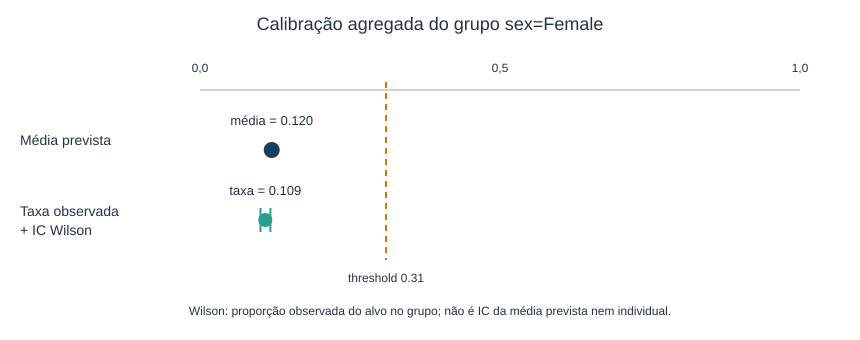

In [4]:
display(SVG(filename=str(outputs['svg'])))

### Insights:
The group's mean prediction can be compared with the Wilson interval for its observed rate, but the quantities have different roles: the first summarizes model scores and the second summarizes binary outcomes. The threshold adds the decision rule, while the interval communicates uncertainty in the group's observed proportion. None of these quantities turns a prediction into individual certainty.

## 5. Demonstration limits

This example uses one official-test row only after the model, calibrator and threshold were frozen. The observed label is used to interpret the case, not to train, select or tune the model. The dataset is historical, the `>50K` label is a census-derived classification, and the result must not be used for real credit, employment, benefits or screening decisions.

### Insights:
The practical application shows how the estimator operates on one observation and how its average behavior can be compared with an observed group proportion. The most defensible interpretation combines the row probability, the explicitly selected threshold, the observed label, the group's mean scores and the Wilson interval for its observed binary proportion.